# TP Integrador: Venta y Recomendación de Eventos 
**Bases de Datos Integradas:** MongoDB + Redis + Neo4j

**Integrantes:** 
* Agustín Ghizzo
* Joaquín Meza

---


## Celda de importaciones y conexiones

In [1]:
import os 
import redis 
import matplotlib.pyplot as plt
from pymongo import MongoClient 
from neo4j import GraphDatabase
from pprint import pprint

# Conexiones
MONGO_HOST = "mongo"
REDIS_HOST = "redis"
NEO4J_HOST = "neo4j"

MONGO_USER = os.getenv("MONGO_INITDB_ROOT_USERNAME", "admin")
MONGO_PASS = os.getenv("MONGO_INITDB_ROOT_PASSWORD", "admin123")
REDIS_PASS = os.getenv("REDIS_PASSWORD", "redis123")
NEO4J_PASS = os.getenv("NEO4J_PASSWORD", "neo4j123")

MONGO_URI = f"mongodb://{MONGO_USER}:{MONGO_PASS}@{MONGO_HOST}:27017/?authSource=admin"
NEO4J_URI = f"bolt://{NEO4J_HOST}:7687"

# Inicialización de conexiones 

try:
    mongo_client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=3000)
    db_mongo = mongo_client["tpIntegrador"]
    mongo_client.admin.command('ping')
    print("Conexión a MongoDB exitosa")

    redis_client = redis.Redis(host=REDIS_HOST, port=6379, password=REDIS_PASS, decode_responses=True)
    redis_client.ping()
    print("Conexión exitosa a Redis")

    neo4j_driver = GraphDatabase.driver(NEO4J_URI, auth=("neo4j", NEO4J_PASS))
    with neo4j_driver.session() as session:
        session.run("RETURN 1")
    print("Conexión a Neo4j exitosa")

except Exception as e:
    print(f"Error de conexion: {e}")


# Se instancia fecha referencia en formato ISO

FECHA_REFERENCIA = "2026-10-01"

Conexión a MongoDB exitosa
Conexión exitosa a Redis
Conexión a Neo4j exitosa


In [2]:
#celda provisoria de importaciones
import sys
import os

sys.path.append(os.path.abspath("../python"))
sys.path.append("/work")

print("1\. Directorio de trabajo actual:", os.getcwd()) 
print("2\. Archivos/Carpetas aquí:", os.listdir('.')) 
if os.path.exists('/work'): 
    print("3\. Contenido de /work:", os.listdir('/work'))

1\. Directorio de trabajo actual: /work
2\. Archivos/Carpetas aquí: ['.ipynb_checkpoints', 'src', 'tpIntegrador.ipynb']
3\. Contenido de /work: ['.ipynb_checkpoints', 'src', 'tpIntegrador.ipynb']


## EJERCICIO 1 - Importaciones y limpieza las bases de datos 
---

In [3]:
# provisorio:

from src.carga_inicial import insert_mongo, insert_neo4j, insert_redis
#Carga de bases de datos
    #Las bases de datos se limpian en el codigo de carga
insert_mongo(db_mongo)
insert_redis(redis_client)
insert_neo4j(neo4j_driver,db_mongo)

Cargando datos en MongoDB
 • Usuarios: 6 insertados
 • Artistas: 6 insertados
 • Lugares: 4 insertados
 • Eventos: 8 insertados
 • Compras: 12 insertados
MongoDB cargado correctamente
Redis cargado con éxito.
Neo4J se cargo correctamente


True


## EJERCICIO 2 - Flujo de compra
* Reservar entradas para un usuario y un evento. Solo se permite si el usuario tiene una sesión
activa y hay disponibilidad suficiente.
* Confirmar una reserva vigente. Se genera la compra con el precio actual del evento. Si la reserva
venció, debe informarse el error.
* Cancelar una reserva, liberando las entradas.
> **Demostrar al menos tres casos:** una compra exitosa, un intento sin disponibilidad suficiente y una
cancelación.

---

### Reservar entradas para un usuario y un evento

In [10]:
from src.consultas_extras import (reservas_vigentes, entradas_vendidas)
#Caso intento sin disponibilidad suficiente
ID_USER = 1
ID_EVENTO = 5
CANTIDAD_INSUFICIENTE = 600
CANTIDAD_SUFICIENTE = 10
def entradas_disponibles(redis_client,db,id_evento,cantidad,cupo):
    entradas_disponibles = cupo - reservas_vigentes(redis_client,id_evento) - entradas_vendidas(db,id_evento)
    if (entradas_disponibles < cantidad):
        print("No hay entradas disponibles para la cantidad pedida")
        return False
    else: return True

def reservar_entrada(id_usuario,id_evento,cant,redis_client,db):
    #Crea la clave de redis
    evento = db.eventos.find_one({"evento_id" : id_evento})
    if not evento:
            print("No se encontro el evento")
            return False
    
    sesion = f"sesion:usuario:{id_usuario}"
    if redis_client.exists(sesion):
        cupo = evento.get("cupo", 0)
        nombre_evento = evento.get("nombre")
        if entradas_disponibles(redis_client,db,id_evento,cant,cupo):
            clave = f"reserva:evento:{id_evento}:usuario:{id_usuario}"
            valor = f"{cant}"
            redis_client.set(clave,valor, ex = 600)
            print(f"Se reservaron {cant} entradas para el evento {nombre_evento}")
        else:
            return False
    else:
            print("El usuario no posee una sesion activa")

#Vuelvo a cargar las sesiones activas
insert_redis(redis_client)
reservar_entrada(ID_USER,ID_EVENTO,CANTIDAD_INSUFICIENTE,redis_client,db_mongo)

#Caso reserva exitosa
reservar_entrada(ID_USER,ID_EVENTO,CANTIDAD_SUFICIENTE,redis_client,db_mongo)

Redis cargado con éxito.
No hay entradas disponibles para la cantidad pedida
Se reservaron 10 entradas para el evento Viento Norte en sala


### Confirmar una reserva vigente.

In [7]:
ID_USER = 1
ID_EVENTO = 5

def confirmar_reserva(db,redis_client,id_usuario,id_evento):
    reserva_vigente = f"reserva:evento:{id_evento}:usuario:{id_usuario}"
    
    if redis_client.exists(reserva_vigente):
        cantidad = int(redis_client.get(reserva_vigente))
        
        ultima_compra = db.compras.find_one(sort=[("compra_id", -1)])
        nueva_id = (ultima_compra["compra_id"] + 1) if ultima_compra else 1

        precio_evento = db.eventos.find_one({"evento_id" : id_evento})
        
        compra_gen = {
                            "compra_id" : nueva_id,
                            "usuario_id" : id_usuario,
                            "evento_id" : id_evento,
                            "cantidad" : cantidad,
                            "precio_unitario" : precio_evento["precio"],
                            "total" : cantidad * precio_evento["precio"],
                            "fecha_compra" : FECHA_REFERENCIA,
                            "estado" : "confirmada"
                        }
        db.compras.insert_one(compra_gen)
        print("La compra se realizo correctamente")
        redis_client.delete(reserva_vigente)
    else: 
        print("ERROR: La reserva esta cancelada o expiro su tiempo")

confirmar_reserva(db_mongo,redis_client,ID_USER,ID_EVENTO)

La compra se realizo correctamente


### Cancelar una reserva.

In [11]:
ID_USER = 1
ID_EVENTO = 5

def cancelar_reserva(db,redis_client,id_usuario,id_evento):
    reserva_cancelada = f"reserva:evento:{id_evento}:usuario:{id_usuario}"
    if redis_client.exists(reserva_cancelada):
        redis_client.delete(reserva_cancelada)
        print("La reserva se cancelo correctamente")
    else: print("No existe una reserva para este evento")

cancelar_reserva(db_mongo,redis_client,ID_USER,ID_EVENTO)

La reserva se cancelo correctamente


## EJERCICIO 3 - 12 CONSULTAS 

1. Usuarios que asistieron a algún evento de "Los Cóndores Eléctricos".
2. Amigos de Juan López que siguen algún artista que también sigue Juan. Mostrar el nombre del amigo y el artista.
3. Recomendar a Juan artistas que siguen sus amigos y que él no sigue, ordenados por cantidad de amigos que los siguen.
4. Para los artistas del punto anterior, listar sus eventos futuros con lugar, ciudad, fecha, precio y entradas disponibles.
5. Artistas similares a los que sigue Lucía Romero y que ella no sigue.
6. Eventos futuros en La Plata con precio menor a $40.000.
7. Cantidad de eventos futuros por género.
8. Total gastado por cada usuario en compras confirmadas, ordenado de mayor a menor.
9. Entradas vendidas por evento, incluyendo los eventos sin ventas.
10. Usuarios conectados en este momento.
11. Reservas vigentes: usuario, evento, cantidad y tiempo restante antes de que venzan.
12. Los 3 géneros más buscados.
---

### 1) Usuarios que asistieron a algún evento de "Los Cóndores Eléctricos"

In [ ]:
artista = db_mongo.artistas.find_one({"nombre":"Los Cóndores Eléctricos"})
artista_id = artista["artista_id"] 

eventos_pasados = db_mongo.eventos.find({"artistas":artista_id, "fecha":{"$lt":FECHA_REFERENCIA} })
eventos_ids = [e["evento_id"] for e in eventos_pasados]

compras_confirmadas = db_mongo.compras.find({"evento_id": {"$in": eventos_ids }, "estado": "confirmada"})

#Quitando duplicados
usuarios_ids = list(set(c["usuario_id"] for c in compras_confirmadas))

usuarios = db_mongo.usuarios.find({"usuario_id": {"$in": usuarios_ids}})

#Imprimiendo

print("Usuarios que asistieron a al menos un evento de 'Los cóndores Eléctricos': ")
for usu in usuarios:
    print(f" {usu['nombre']} (ID: {usu['usuario_id']})")


### 2) Amigos de Juan López que siguen algún artista que también sigue Juan. Mostrar el nombre del amigo y el artista.

In [ ]:
query_2 = """
MATCH (juan:Usuario {nombre: "Juan López"})-[:AMIGO_DE]-(amigo:Usuario), (juan)-[:SIGUE]->(artista:Artista), (amigo)-[:SIGUE]->(artista)
RETURN amigo.nombre, artista.nombre
"""

with neo4j_driver.session() as session:
    for r in session.run(query_2):
        print(f"Con el amigo: {r['amigo.nombre']} comparten al artista: {r['artista.nombre']}")

### 3) Recomendar a Juan artistas que siguen sus amigos y que él no sigue, ordenados por cantidad de amigos que los siguen.

In [ ]:
query_3= """
MATCH (juan:Usuario {nombre: "Juan López"})-[:AMIGO_DE]-(amigo:Usuario)-[:SIGUE]->(artista:Artista)
WITH juan, artista, amigo, EXISTS((juan)-[:SIGUE]->(artista)) AS juan_ya_lo_sigue
WHERE NOT juan_ya_lo_sigue
RETURN artista.nombre, COUNT(amigo) AS cantidad_amigos
ORDER BY cantidad_amigos DESC
"""

with neo4j_driver.session() as session:
    for r in session.run(query_3):
        print(f"Artista recomendado: {r['artista.nombre']} , seguido por {r['cantidad_amigos']} de tus amigos")


### 4) Para los artistas del punto anterior, listar sus eventos futuros con lugar, ciudad, fecha, precio y entradas disponibles.

In [ ]:
print()
print("Inciso 4: ")

with neo4j_driver.session() as session:
    nombres_recomendados = [r['artista.nombre'] for r in session.run(query_3)]

artistas_mongo = db_mongo.artistas.find({"nombre": {"$in": nombres_recomendados}})
ids_recomendados = [artista['artista_id'] for artista in artistas_mongo]

eventos_futuros_recomendados = db_mongo.eventos.find({
    'artistas':{'$in':ids_recomendados},
    'fecha':{'$gt':FECHA_REFERENCIA},
    'estado':'activo'
})
for e in eventos_futuros_recomendados:
    lugar = db_mongo.lugares.find_one({
        'lugar_id':e['lugar_id']
    })
    print(f"Evento recomendado: {e['nombre']} el {e['fecha']} a ${e['precio']} en {lugar['ciudad']}")



### 5) Artistas similares a los que sigue Lucía Romero y que ella no sigue.

In [ ]:
print()
print("Inciso 5: ")
query_5 = """
MATCH (lucia:Usuario {nombre: "Lucía Romero"})-[:SIGUE]->(a:Artista)-[:SIMILAR_A]-(s:Artista)
WHERE NOT (lucia)-[:SIGUE]->(s)
RETURN s.nombre AS similar, collect(DISTINCT a.nombre) AS porque_sigue_a
"""
with neo4j_driver.session() as session:
    for r in session.run(query_5):
        print(f"{r['similar']} (similar a {', '.join(r['porque_sigue_a'])})")

### 6) Eventos futuros en La Plata con precio menor a $40.000.

In [ ]:
print()
print('Inciso 6: ')
lugares_lp = [l["lugar_id"] for l in db_mongo.lugares.find({"ciudad": "La Plata"})]
eventos_futuros_baratos = db_mongo.eventos.find({
    'lugar_id':{'$in': lugares_lp},
    'precio':{'$lt':40000},
    'estado':'activo',
    'fecha': {'$gt': FECHA_REFERENCIA}
})

for evento in eventos_futuros_baratos:
    lugar = db_mongo.lugares.find_one({'lugar_id':evento['lugar_id']})
    print(f"Te recomendamos asistir a {evento['nombre']} por solo ${evento['precio']} el día: {evento['fecha']} en {lugar['nombre']}")


### 7) Cantidad de eventos futuros por género.

In [ ]:
print()
print('Inciso 7')
#Uso una agreggation pipeline

pipeline_7 = [
    {'$match': {'fecha': {'$gte':FECHA_REFERENCIA}}},
    {'$group': {'_id': '$genero', 'cantidad_eventos':{'$sum':1}}}
]

ev_futuros_por_genero = db_mongo.eventos.aggregate(pipeline_7)


for resultado in ev_futuros_por_genero:
    print(f"{resultado['_id']}: {resultado['cantidad_eventos']} eventos")


### 8) Total gastado por cada usuario en compras confirmadas, ordenado de mayor a menor.

In [ ]:
print()
print('Inciso 8')

pipeline_8 = [
    {'$match':{'estado':'confirmada'}},
    {'$group':{'_id': '$usuario_id','total':{'$sum':'$total'}}},
    {'$sort':{'total': -1}}
]

for r in db_mongo.compras.aggregate(pipeline_8):
    u = db_mongo.usuarios.find_one({'usuario_id': r['_id']})
    print(f"{u['nombre']}: ${r['total']:,}")

###  9) Entradas vendidas por evento, incluyendo los eventos sin ventas.

In [ ]:
print("Inciso 9: Entradas vendidas por evento")

#Traigo todos los eventos
todos_los_eventos = db_mongo.eventos.find({})

for evento in todos_los_eventos:
    compras_del_evento = db_mongo.compras.find({
        "evento_id": evento["evento_id"],
        "estado": "confirmada"
    })

    total_entradas = sum([compra["cantidad"] for compra in compras_del_evento])
    
    print(f"Evento: {evento['nombre']} - Entradas vendidas: {total_entradas}")

### 10. Usuarios conectados en este momento.

In [ ]:
#provisorio
claves_activas = redis_client.keys('*') 

if not claves_activas:
    print("No hay ningún usuario conectado en este momento.")

for clave in claves_activas:
    valor = redis_client.get(clave)
    
    print(f"Registro activo en Redis -> Clave: {clave}, Valor: {valor}")

### 11. Reservas vigentes: usuario, evento, cantidad y tiempo restante antes de que venzan.

In [ ]:
claves_reservas = redis_client.keys('reserva:*')


if not claves_reservas:
    print("No hay reservas vigentes en este momento.")

#redis_client.setex("reserva:usuario_2:evento_1", 300, "cantidad: 2")

for clave in claves_reservas:
    # 2. Le preguntamos a Redis los segundos exactos que le quedan de vida a esa llave
    tiempo_restante = redis_client.ttl(clave)
    
    # 3. Traemos los datos guardados (usuario, evento, cantidad)
    datos_reserva = redis_client.get(clave)
    
    print(f"Reserva: {clave} | Datos: {datos_reserva} | Vence en: {tiempo_restante} segundos")

### 12. Los 3 géneros más buscados.

In [ ]:
top3 = redis_client.zrevrange("busquedas:generos", 0, 2, withscores=True)
for genero, puntaje in top3:
    print(f"{genero}: {int(puntaje)} búsquedas")

## Ejercicio 4 - Estadísticas y gráficos

Generar las siguientes estadísticas, mostrando el valor para cada elemento **(no solo el máximo)**:
* Cantidad de seguidores por artista.
* Recaudación por evento (compras confirmadas).
* Entradas vendidas por lugar.
* Cantidad de búsquedas por género.

> Representar al menos dos de estas estadísticas con gráficos hechos con matplotlib.

> Los datos de los gráficos deben obtenerse consultando las bases, no desde las listas de Python del dataset.

---

In [7]:
# Función reutilizada de un proyecto anterior, adaptada para jupyterlab:

def generar_grafico_generico(datos_x, datos_y, tipo_grafico="bar", titulo="", x_etiqueta="", y_etiqueta="", **kwargs):
    """
    Crea un gráfico de Matplotlib según los argumentos recibidos y lo renderiza en Streamlit
    """
    fig, ax = plt.subplots(figsize=kwargs.get('figsize', (10, 6)))
    if tipo_grafico == 'bar':
        ax.bar(datos_x, datos_y, color=kwargs.get('color', '#4db6ac'))
        plt.xticks(rotation=45)
    elif tipo_grafico == 'line':
        ax.plot(datos_x, datos_y, marker='o', color=kwargs.get('color', '#e74c3c'))
        plt.xticks(rotation=45)
    elif tipo_grafico == 'pie':
        ax.pie(datos_y, labels=datos_x, autopct='%1.1f%%', shadow=True)
    elif tipo_grafico == 'barh':
        ax.barh(datos_x, datos_y, color=kwargs.get('color', '#4db6ac'))
        labelsize = kwargs.get('labelsize', None)
        if labelsize:
            ax.tick_params(axis='y', labelsize=labelsize)

    ax.set_title(titulo)
    if tipo_grafico != "pie":
        ax.set_xlabel(x_etiqueta)
        ax.set_ylabel(y_etiqueta)

    fig.tight_layout()
    plt.show(fig)

### Mostrando cantidad de seguidores por artista

  Pulso Nocturno: 3 seguidores
  Radio Neón: 3 seguidores
  Cumbia Satelital: 2 seguidores
  La Marea Sur: 2 seguidores
  Los Cóndores Eléctricos: 2 seguidores
  Viento Norte: 1 seguidores


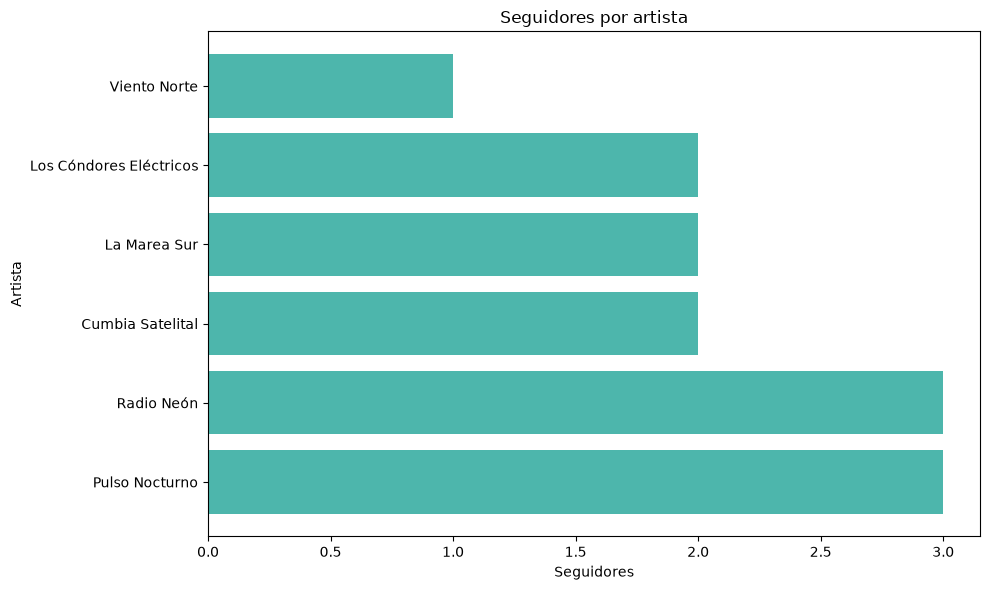

In [8]:
query_seguidores = """
MATCH (a:Artista)
OPTIONAL MATCH (u:Usuario)-[:SIGUE]->(a)
RETURN a.nombre AS artista, count(u) AS seguidores
ORDER BY seguidores DESC, artista
"""

with neo4j_driver.session() as session:
    res = session.run(query_seguidores).data()

for r in res:
    print(f"  {r['artista']}: {r['seguidores']} seguidores")

artistas_x = [r["artista"] for r in res]
seguidores_y = [r["seguidores"] for r in res]

generar_grafico_generico(artistas_x, seguidores_y, "barh","Seguidores por artista", "Seguidores", "Artista")

### Cantidad de búsquedas por género.

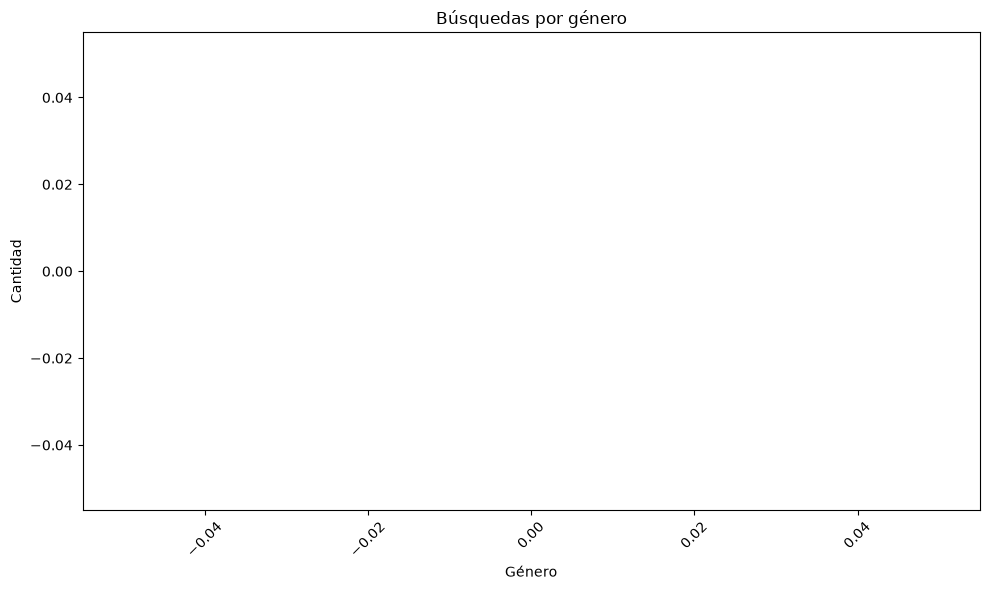

In [9]:
#Provisorio
busq = redis_client.zrevrange("busquedas:genero", 0, -1, withscores=True)
generos = [g for g, _ in busq]
cantidades = [int(c) for _, c in busq]

for g, c in zip(generos, cantidades):
    print(f"{g}: {c} búsquedas")

generar_grafico_generico(generos, cantidades, "bar","Búsquedas por género", "Género", "Cantidad")

### Entradas vendidas por lugar.

In [ ]:
pipeline_recaudacion = [
    {"$lookup": {"from": "compras", "localField": "evento_id","foreignField": "evento_id","pipeline": [{"$match": {"estado": "confirmada"}}],"as": "cs"}},
    {"$project": {"_id": 0, "evento": "$nombre","recaudacion": {"$sum": "$cs.total"}}},
    {"$sort": {"recaudacion": -1, "evento": 1}
    }]

resultados = list(db_mongo.eventos.aggregate(pipeline_recaudacion))
nombres_eventos = [r["evento"] for r in resultados]
recaudacion = [r["recaudacion"] for r in resultados]

print("Recaudación por evento (compras confirmadas):")
for r in resultados:
    print(f"  {r['evento']}: ${r['recaudacion']:,}")

generar_grafico_generico(nombres_eventos, recaudacion, "barh","Recaudación por evento", "Recaudación ($)", "Evento")

### Entradas vendidas por lugar

In [ ]:
pipeline_lugares = [
    {"$match": {"estado": "confirmada"}},
    {"$lookup": {"from": "eventos","localField": "evento_id","foreignField": "evento_id","as": "ev"}},
    {"$unwind": "$ev"},         
    {"$group": {"_id": "$ev.lugar_id", "cantidad": {"$sum": "$cantidad"}}}
]

vendidas_lugar = {r["_id"]: r["cantidad"] for r in db_mongo.compras.aggregate(pipeline_lugares)}

nombres_lugares = []
entradas = []
for l in db_mongo.lugares.find().sort("lugar_id", 1):  
    cant = vendidas_lugar.get(l["lugar_id"], 0)
    nombres_lugares.append(l["nombre"])
    entradas.append(cant)
    print(f"  {l['nombre']} ({l['ciudad']}): {cant} entradas")

generar_grafico_generico(nombres_lugares, entradas, "pie", "Entradas vendidas por lugar")

## Ejercicio 5 - Modificaciones
1. Aumentar un 10% el precio de los eventos futuros en Rosario.
2. Agregar el servicio "accesibilidad" al lugar con id 2.
3. Cancelar el evento 7.
 * El evento queda cancelado.
 * Sus compras pasan a estado reembolsada.
 * No debe quedar disponibilidad ni reservas de ese evento.
 * No debe aparecer en recomendaciones.
Eliminar al usuario Tomás Herrera (id 6) del sistema. Decidir y justificar qué pasa con sus
compras.
5. Eliminar todas las amistades de un usuario a elección.
En los puntos 3 a 5, los cambios deben reflejarse en todas las bases donde haya datos afectados.
Después de cada modificación, mostrar una consulta que evidencie el cambio.


In [4]:
from src.modificaciones import aumentar_precio_rosario
aumentar_precio_rosario(db_mongo)

• Radio Neón Tour -> Nuevo precio: 24200.0


In [5]:
from src.modificaciones import agregar_servicio2
agregar_servicio2(db_mongo)

'Informacion del lugar 2'
{'_id': ObjectId('6ad7ed2afd2d3dde0f05d554'),
 'capacidad': 800,
 'ciudad': 'La Plata',
 'lugar_id': 2,
 'nombre': 'Sala Diagonal',
 'servicios': ['bar', 'accesibilidad']}


In [12]:
from src.modificaciones import cancelar_evento7
cancelar_evento7(db_mongo,redis_client)
evento = db_mongo.eventos.find_one({"evento_id" : 7})
pprint(f"Evento 7:{evento}")
compra = list(db_mongo.compras.find({"evento_id" : 7}))
pprint(f"Compras del evento 7: {compra}")
reserva = f"reserva:evento:7:*"
if(reserva):
   print("La reserva no se elimino")
else: print("La reserva se elimino correctamente")

("Evento 7:{'_id': ObjectId('6ade38ff801647afc4508a66'), 'evento_id': 7, "
 "'nombre': 'Radio Neón Tour', 'artistas': [6], 'lugar_id': 4, 'fecha': "
 "'2026-10-10', 'genero': 'rock', 'precio': 22000, 'cupo': 200, 'estado': "
 "'cancelado'}")
("Compras del evento 7: [{'_id': ObjectId('6ade38ff801647afc4508a71'), "
 "'compra_id': 10, 'usuario_id': 6, 'evento_id': 7, 'cantidad': 1, "
 "'precio_unitario': 22000, 'total': 22000, 'fecha_compra': '2026-09-15', "
 "'estado': 'anulado'}]")
("Evento 7:{'_id': ObjectId('6ade38ff801647afc4508a66'), 'evento_id': 7, "
 "'nombre': 'Radio Neón Tour', 'artistas': [6], 'lugar_id': 4, 'fecha': "
 "'2026-10-10', 'genero': 'rock', 'precio': 22000, 'cupo': 200, 'estado': "
 "'cancelado'}")
("Compras del evento 7: [{'_id': ObjectId('6ade38ff801647afc4508a71'), "
 "'compra_id': 10, 'usuario_id': 6, 'evento_id': 7, 'cantidad': 1, "
 "'precio_unitario': 22000, 'total': 22000, 'fecha_compra': '2026-09-15', "
 "'estado': 'anulado'}]")
La reserva no se elimino


In [17]:
from src.modificaciones import eliminar_usuario6
ID_USER = 6
eliminar_usuario6(db_mongo,redis_client,ID_USER,neo4j_driver) 
usuario = db_mongo.usuarios.find_one({"usuario_id" : ID_USER})
compra_usuario = db_mongo.compras.find({"usuario_id" : ID_USER})
pprint(f"Usuario --> {usuario}")
for compra in compra_usuario:
    pprint(f"Compras del usuario eliminado:{compra}")
#Consulta para verificar relaciones 
consulta = """
            MATCH (u:Usuario {usuario_id:$id})
            OPTIONAL MATCH (u)-[r:AMIGO_DE]-(amigo:Usuario)
            RETURN
                count(r) AS total_relaciones
            """
with neo4j_driver.session() as session:
    resultado = session.run(consulta, id=ID_USER).single()
    print(f"Total de relaciones encontradas:{resultado['total_relaciones']}")

El usuario no tiene una sesion activa
El usuario no tiene una reserva activa
'Usuario --> None'
("Compras del usuario eliminado:{'_id': ObjectId('6ade4596a195de3dcf8b7809'), "
 "'compra_id': 10, 'usuario_id': 6, 'evento_id': 7, 'cantidad': 1, "
 "'precio_unitario': 22000, 'total': 22000, 'fecha_compra': '2026-09-15', "
 "'estado': 'anulado'}")
Total de relaciones encontradas:0


In [18]:
from src.modificaciones import eliminar_amistades
ID_USER = 3
eliminar_amistades(ID_USER,db_mongo,neo4j_driver)
consulta = """
            MATCH (u:Usuario {usuario_id:$id})
            OPTIONAL MATCH (u)-[r:AMIGO_DE]-(amigo:Usuario)
            RETURN
                count(r) AS total_relaciones
            """
with neo4j_driver.session() as session:
    resultado = session.run(consulta, id=ID_USER).single()
    print(f"Total de relaciones encontradas:{resultado['total_relaciones']}")

Total de relaciones encontradas:0
